# Contornos

In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
from src.preprocessamento import para_cinza
from src.segmentacao import binarizar, otsu
from src.morfologia import pos_processar
from src.caracteristicas import maior_contorno, desenhar_contorno

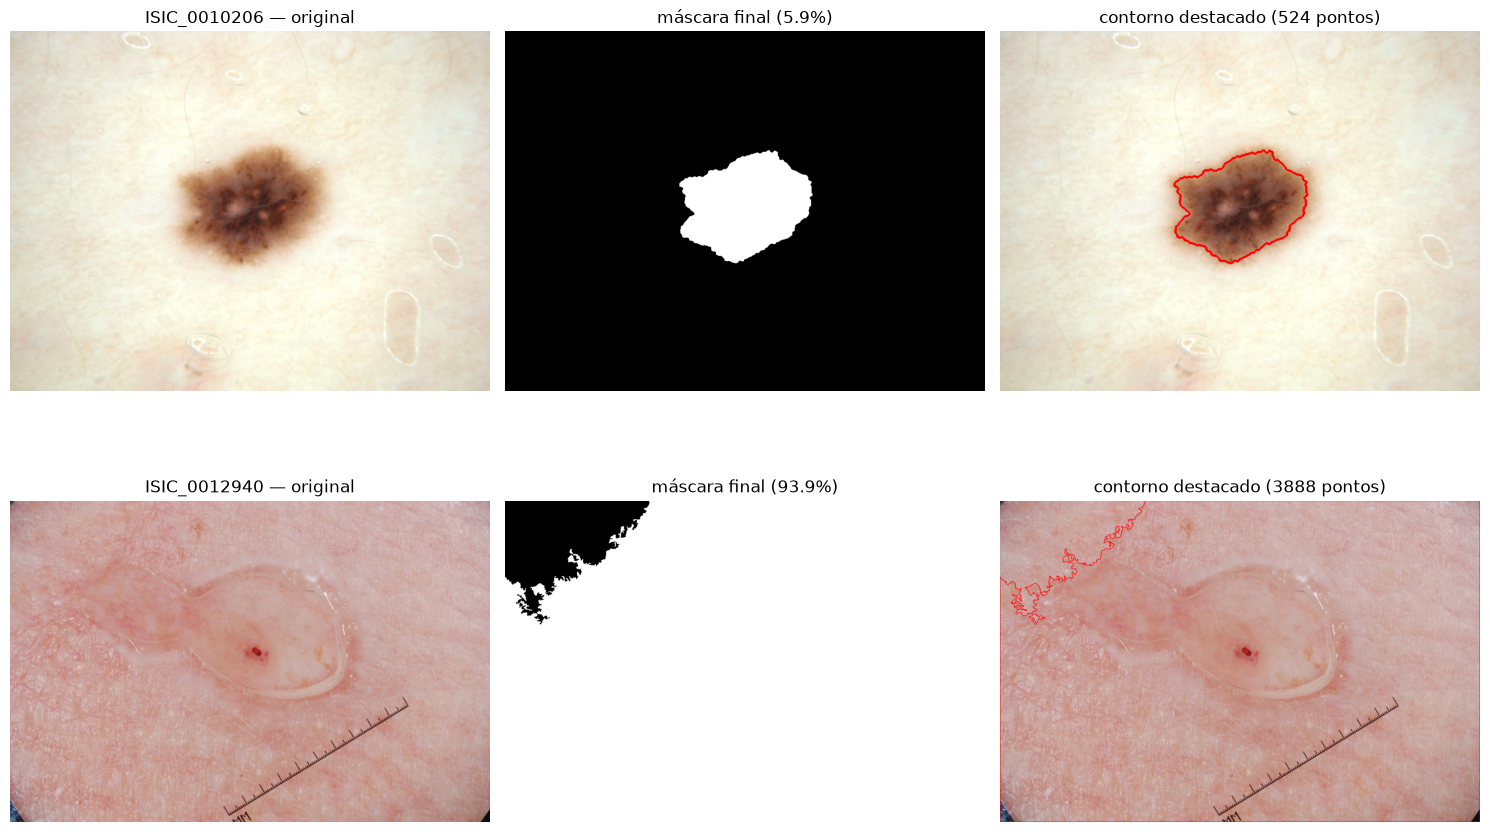

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"]):
    img = carregar_imagem(PASTA_IMAGENS / nome)
    cinza = para_cinza(img)
    nome_curto = Path(nome).stem

    msk = pos_processar(binarizar(cinza, otsu(cinza), invertida=True))   # pipeline completo
    contorno = maior_contorno(msk)
    destacado = desenhar_contorno(img, contorno)

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"{nome_curto} — original")
    axes[i, 1].imshow(msk, cmap="gray")
    axes[i, 1].set_title(f"máscara final ({msk.mean()/255*100:.1f}%)")
    axes[i, 2].imshow(destacado)
    axes[i, 2].set_title(f"contorno destacado ({len(contorno)} pontos)")
    for ax in axes[i]:
        ax.axis("off")

fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "contornos" / "contornos.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)